In [5]:
import pandas as pd
df=pd.read_csv("../data/processed/onlineRetail_cleaned.csv")

In [6]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 392692 entries, 0 to 392691
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  int64         
 1   StockCode    392692 non-null  str           
 2   Description  392692 non-null  str           
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[us]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  float64       
 7   Country      392692 non-null  str           
 8   TotalPrice   392692 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(2), str(3)
memory usage: 27.0 MB


In [8]:
df["InvoiceDate"].min(), df["InvoiceDate"].max()

(Timestamp('2010-12-01 08:26:00'), Timestamp('2011-12-09 12:50:00'))

In [9]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

In [10]:
reference_date

Timestamp('2011-12-10 12:50:00')

In [11]:
recency=df.groupby("CustomerID")["InvoiceDate"].max()

In [12]:
recency.head(10)

CustomerID
12346.0   2011-01-18 10:01:00
12347.0   2011-12-07 15:52:00
12348.0   2011-09-25 13:13:00
12349.0   2011-11-21 09:51:00
12350.0   2011-02-02 16:01:00
12352.0   2011-11-03 14:37:00
12353.0   2011-05-19 17:47:00
12354.0   2011-04-21 13:11:00
12355.0   2011-05-09 13:49:00
12356.0   2011-11-17 08:40:00
Name: InvoiceDate, dtype: datetime64[us]

i kena grupu klientat sipas id-s edhe sipas blerjes ttyre t fundit max()-blerja e fundit merret kurse min()-blerja ma e hershme

In [13]:
recency=(reference_date - recency).dt.days

In [14]:
recency.head(10)

CustomerID
12346.0    326
12347.0      2
12348.0     75
12349.0     19
12350.0    310
12352.0     36
12353.0    204
12354.0    232
12355.0    214
12356.0     23
Name: InvoiceDate, dtype: int64

In [15]:
recency.describe()

count    4338.000000
mean       92.536422
std       100.014169
min         1.000000
25%        18.000000
50%        51.000000
75%       142.000000
max       374.000000
Name: InvoiceDate, dtype: float64

In [16]:
recency.name="Recency"

In [17]:
recency.head(10)

CustomerID
12346.0    326
12347.0      2
12348.0     75
12349.0     19
12350.0    310
12352.0     36
12353.0    204
12354.0    232
12355.0    214
12356.0     23
Name: Recency, dtype: int64

In [18]:
frequency=df.groupby("CustomerID")["InvoiceNo"].nunique()

In [19]:
frequency.name="Frequency"

In [20]:
frequency.head(10)

CustomerID
12346.0    1
12347.0    7
12348.0    4
12349.0    1
12350.0    1
12352.0    8
12353.0    1
12354.0    1
12355.0    1
12356.0    3
Name: Frequency, dtype: int64

ktu e kena kriju frequency qe me dit saktesisht sa blerje i ka bo klienti,e kena perdor nunique n menyre qe mi gjet veq invoices unike jo mi numru krejt se psh klienti ka mujt me ni blerje mi ble 7 produkte ,saktesisht per ni klient sa blerje te ndryshme(invoice ka)?

In [21]:
monetary = df.groupby("CustomerID")["TotalPrice"].sum()

In [22]:
monetary.head(10)

CustomerID
12346.0    77183.60
12347.0     4310.00
12348.0     1797.24
12349.0     1757.55
12350.0      334.40
12352.0     2506.04
12353.0       89.00
12354.0     1079.40
12355.0      459.40
12356.0     2811.43
Name: TotalPrice, dtype: float64

In [23]:
monetary.name="Monetary"

In [24]:
monetary.head(10)

CustomerID
12346.0    77183.60
12347.0     4310.00
12348.0     1797.24
12349.0     1757.55
12350.0      334.40
12352.0     2506.04
12353.0       89.00
12354.0     1079.40
12355.0      459.40
12356.0     2811.43
Name: Monetary, dtype: float64

In [25]:
df=pd.concat([recency, frequency, monetary], axis=1)

In [26]:
df.info()

<class 'pandas.DataFrame'>
Index: 4338 entries, 12346.0 to 18287.0
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Recency    4338 non-null   int64  
 1   Frequency  4338 non-null   int64  
 2   Monetary   4338 non-null   float64
dtypes: float64(1), int64(2)
memory usage: 135.6 KB


In [27]:
rfm = df.copy()

In [28]:
rfm.head(10)

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40


In [29]:
df = pd.read_csv("../data/processed/onlineRetail_cleaned.csv")

In [30]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [31]:
df.shape

(392692, 9)

In [32]:
rfm = pd.concat([recency, frequency, monetary], axis=1)

In [33]:
rfm.head(10)

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40


In [34]:
rfm.info()

<class 'pandas.DataFrame'>
Index: 4338 entries, 12346.0 to 18287.0
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Recency    4338 non-null   int64  
 1   Frequency  4338 non-null   int64  
 2   Monetary   4338 non-null   float64
dtypes: float64(1), int64(2)
memory usage: 135.6 KB


In [35]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [36]:
!pip install matplotlib
import matplotlib.pyplot as plt


[notice] A new release of pip is available: 23.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


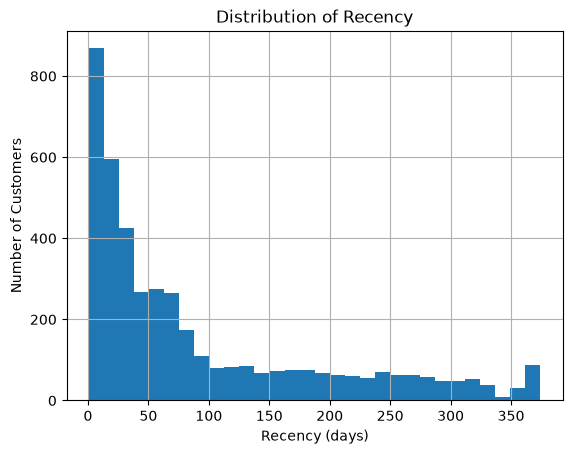

In [37]:
rfm["Recency"].hist(bins=30)
plt.xlabel("Recency (days)")
plt.ylabel("Number of Customers")
plt.title("Distribution of Recency")
plt.show()

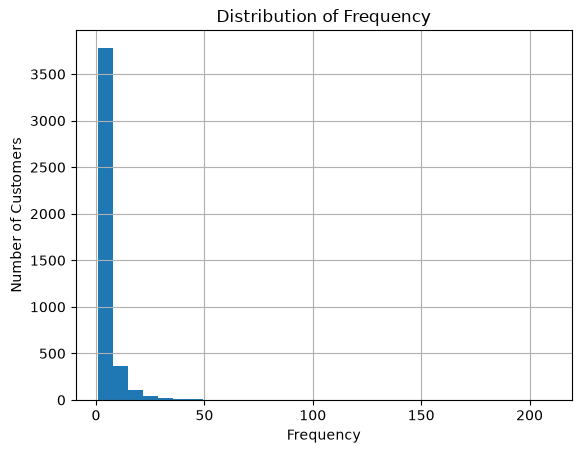

In [38]:
rfm["Frequency"].hist(bins=30)
plt.xlabel("Frequency")
plt.ylabel("Number of Customers")
plt.title("Distribution of Frequency")
plt.show()

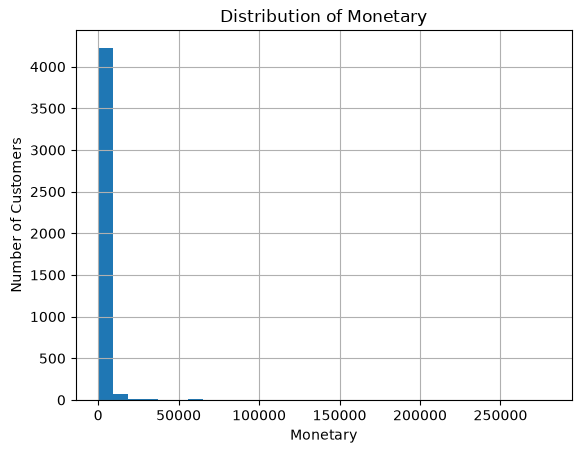

In [39]:
rfm["Monetary"].hist(bins=30)
plt.xlabel("Monetary")
plt.ylabel("Number of Customers")
plt.title("Distribution of Monetary")
plt.show()

historigramet per secilin

In [40]:
rfm[["Recency", "Frequency", "Monetary"]].quantile([0.90, 0.95, 0.99])

,Recency,Frequency,Monetary
0.90,263.0,9.0,3640.8410
0.95,312.0,13.0,5789.9995
0.99,369.0,30.0,19780.4878


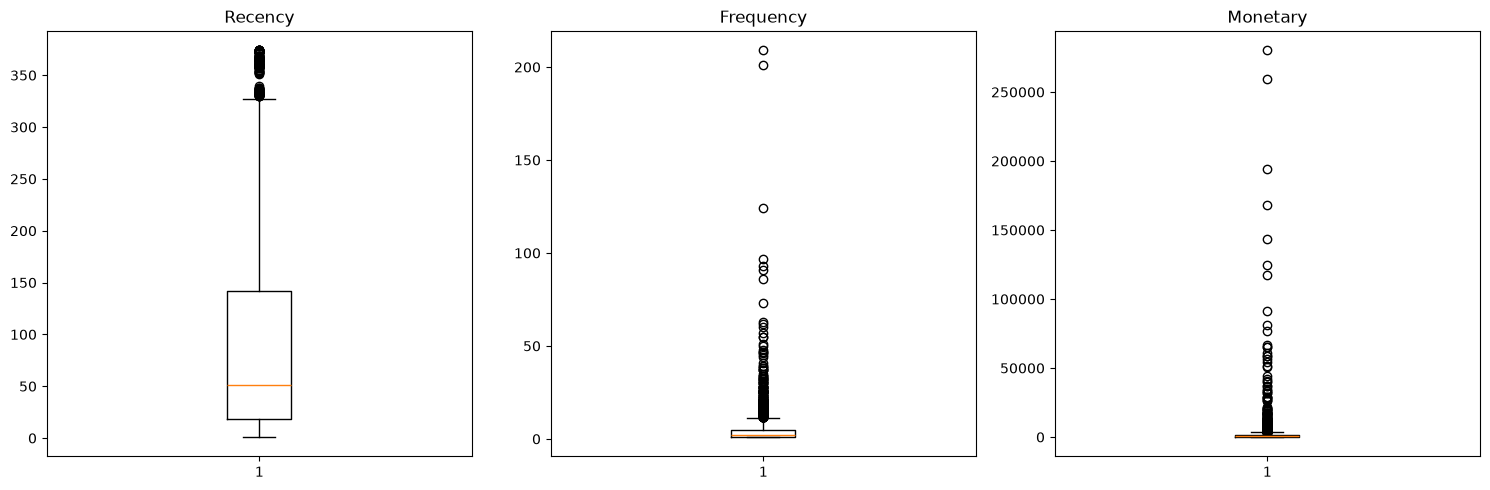

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].boxplot(rfm["Recency"])
axes[0].set_title("Recency")

axes[1].boxplot(rfm["Frequency"])
axes[1].set_title("Frequency")

axes[2].boxplot(rfm["Monetary"])
axes[2].set_title("Monetary")

plt.tight_layout()

In [42]:
rfm_1=rfm.copy()

In [43]:
import numpy as np  
rfm_1["Frequency"]=np.log1p(rfm_1["Frequency"])
rfm_1["Monetary"]=np.log1p(rfm_1["Monetary"])

e kena bo t pershtatshem per machine learning algorithm permes logut pershkak qe disa vlera te frequency edhe monetary jon teper t nalta e tani do tjera teper t vogla ,log1p pershkak qe osht njejt si log1+x ma e pershtatshme se nese ka naj vlere 0 ,log i 0 nuk ekziston edhe per kit arsye permes log1p bohet 1 edhe skemi errors

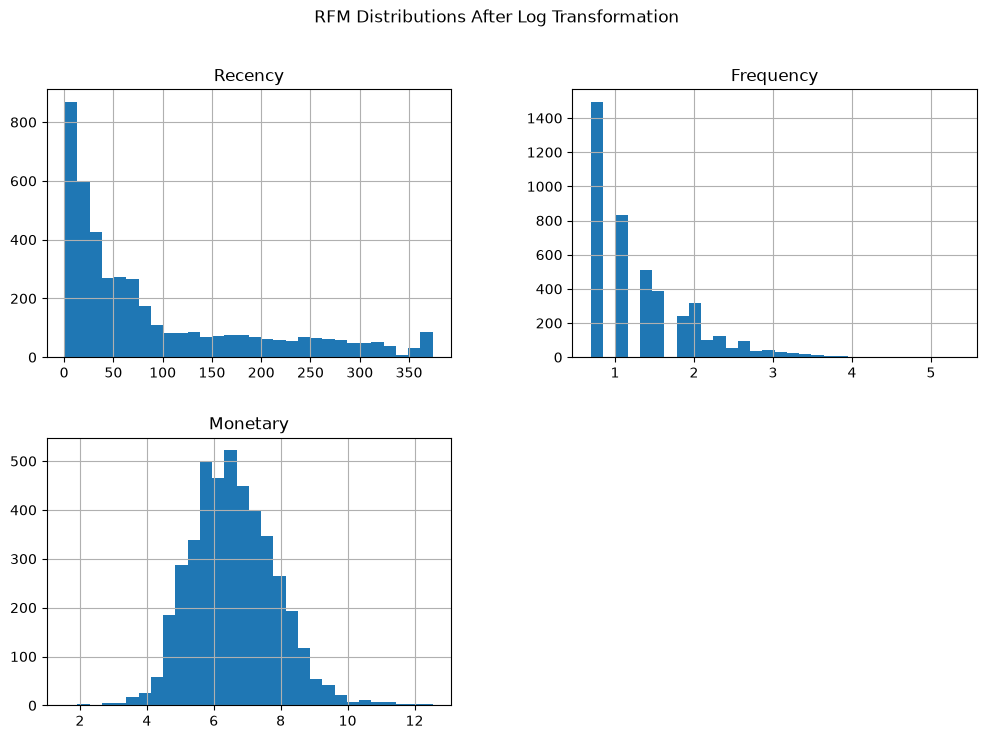

In [44]:
rfm_1[["Recency", "Frequency", "Monetary"]].hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("RFM Distributions After Log Transformation")
plt.show()

In [45]:
from sklearn.preprocessing import StandardScaler
features = ["Recency", "Frequency", "Monetary"]
scaler = StandardScaler()
rfm_scaled=scaler.fit_transform(rfm_1[features])

In [46]:
type(rfm_scaled)

numpy.ndarray

In [47]:

rfm_scaled_df=pd.DataFrame(
    rfm_scaled,
    columns=features,
    index=rfm_1.index
)

rfm_scaled_df.head(10)

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,2.334574,-0.955214,3.707716
12347.0,-0.905340,1.074425,1.414903
12348.0,-0.175360,0.386304,0.720024
12349.0,-0.735345,-0.955214,0.702287
12350.0,2.174578,-0.955214,-0.614514
12352.0,-0.565349,1.246868,0.984108
12353.0,1.114606,-0.955214,-1.659989
12354.0,1.394599,-0.955214,0.315129
12355.0,1.214604,-0.955214,-0.362767


In [48]:
rfm_scaled_df.describe().round(2)

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-0.92,-0.96,-4.00
25%,-0.75,-0.96,-0.68
50%,-0.42,-0.36,-0.07
75%,0.49,0.65,0.66
max,2.81,5.86,4.73


ktu i kena bo scale 

In [49]:
from sklearn.cluster import KMeans
inertia = []
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(rfm_scaled)
    
    inertia.append(kmeans.inertia_)

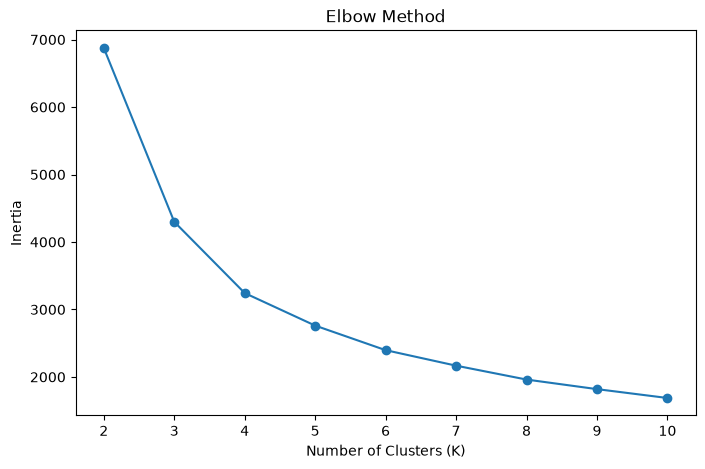

In [50]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

permes elbow method- qiut ku po bijn drastikisht vlerat e gjejna optimal K klusters dmth,te rasti jon optimal clusters = 4 po e provojna edhe me siluete scores

In [51]:
from sklearn.metrics import silhouette_score

In [52]:
silhouette_scores = []
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(rfm_scaled)
    
    score = silhouette_score(rfm_scaled, kmeans.labels_)
    
    silhouette_scores.append(score)

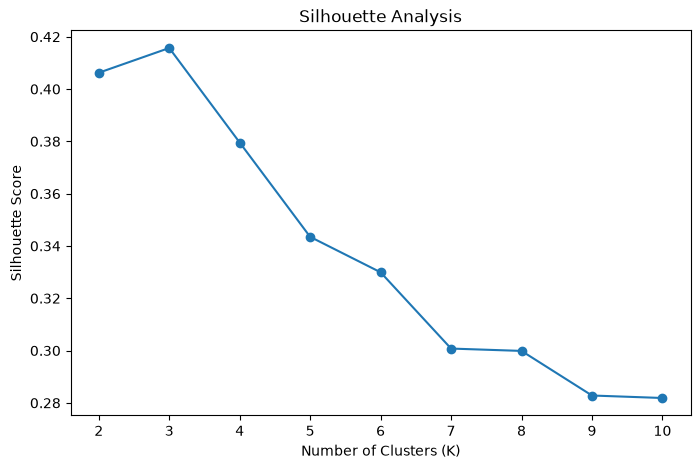

In [53]:
plt.figure(figsize=(8, 5))
plt.plot(range(2,11), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.show()

In [54]:
for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K={k}: Silhouette Score = {score:.3f}")

K=2: Silhouette Score = 0.406
K=3: Silhouette Score = 0.416
K=4: Silhouette Score = 0.380
K=5: Silhouette Score = 0.343
K=6: Silhouette Score = 0.330
K=7: Silhouette Score = 0.301
K=8: Silhouette Score = 0.300
K=9: Silhouette Score = 0.283
K=10: Silhouette Score = 0.282


ktu po na del tjeter rezultat dmth k=3 -- 416 si rezultati te elbow

In [55]:
kmeans=KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

In [56]:
rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(2)

,Recency,Frequency,Monetary
Cluster,,,
0,30.10,9.84,5492.04
1,255.11,1.39,397.17
2,54.70,2.05,612.71


Cluster 0 - Klientet ma t mire  me 30.10dite,9.84 blerje,5492 shpenzime ne para
Cluster 1 - Klientet ne rrezik per humbje,skan ble qe 255.1 dite kan bo veq 1.39 b;lerje edhe kan shpenzu veq 397 para
Cluster 2 - kliente potencial jo qaq t mire sa ne cluster 0 amo  kan ble qe 54 dite i kan bo 2 blerje kan shpenzu 612

In [57]:
rfm["Cluster"].value_counts().sort_index()

Cluster
0    1320
1     981
2    2037
Name: count, dtype: int64

ne Cluster 0 jon 1320 kliente 
ne Cluster 1 jane 981 kliente
ne Cluster 2 ka mas shumti 2037


Perdorim strategji per secilin klient psh te cluster 0 loyalty programs,vip offers,personalized recommendations , early access

te cluster 1 tentojna mi rikthy klientat permes discounts,reactivation campaigns dhe rekomandime t personalizume

te cluster 2 i shtyjna drejt clusterit 0 ,offers,recommandations ,loyalty programs

Gati gjysma e klienteve jon potential clients per me kon klient besnike,30perqind e tynev jon high level customers e dikun 22 perqind jon at risk clients

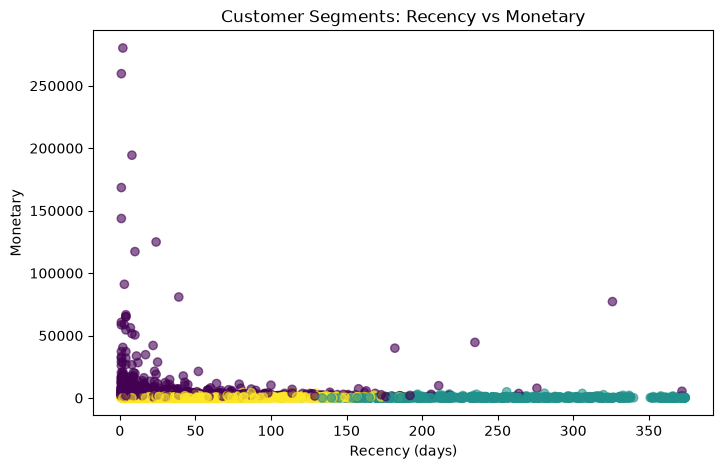

In [58]:
plt.figure(figsize=(8, 5))

plt.scatter(
    rfm["Recency"],
    rfm["Monetary"],
    c=rfm["Cluster"],
    alpha=0.6
)

plt.xlabel("Recency (days)")
plt.ylabel("Monetary")
plt.title("Customer Segments: Recency vs Monetary")

plt.show()

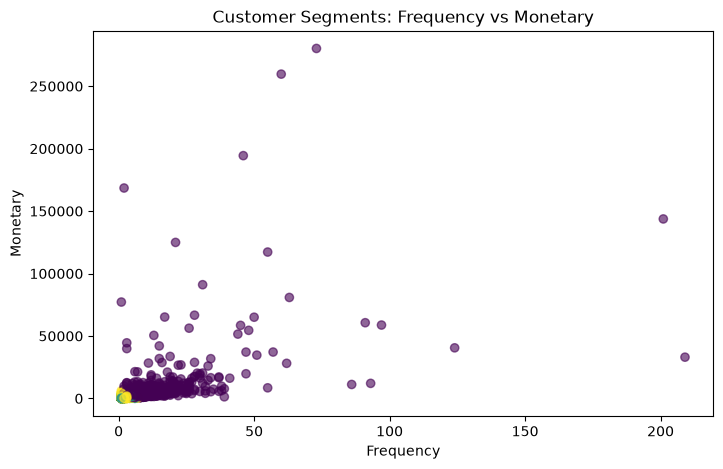

In [59]:
plt.figure(figsize=(8, 5))

plt.scatter(
    rfm["Frequency"],
    rfm["Monetary"],
    c=rfm["Cluster"],
    alpha=0.6
)

plt.xlabel("Frequency")
plt.ylabel("Monetary")
plt.title("Customer Segments: Frequency vs Monetary")

plt.show()

In [60]:
rfm.groupby("Cluster")[["Frequency", "Monetary"]].agg(
    ["mean", "min", "max"]
).round(2)

Frequency          Monetary                   
             mean min  max     mean     min        max
Cluster                                               
0            9.84   1  209  5492.04  621.68  280206.02
1            1.39   1    7   397.17    3.75    4959.10
2            2.05   1    7   612.71    6.20    6207.67

e kom analizu segmentin frequency vs monetary per secilin cluster tu e gjet mesataren e blerjeve dhe mesataren e shpenzimeve ne para,minimalen dhe maksimalen e blerjeve dhe minimalen dhe maksimalen e shpenzimeve ne para

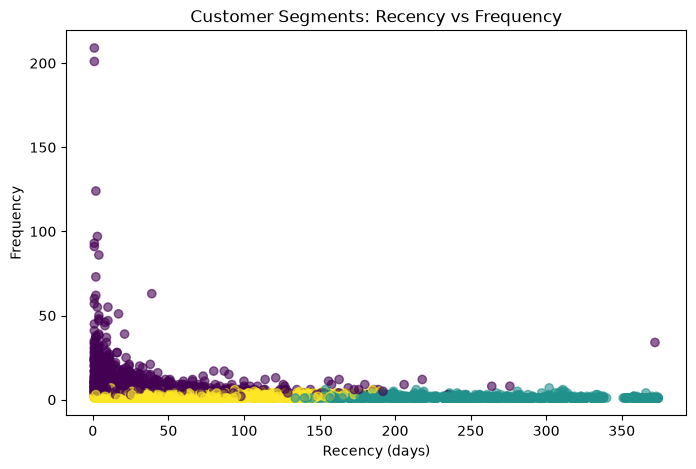

In [61]:
plt.figure(figsize=(8, 5))

plt.scatter(
    rfm["Recency"],
    rfm["Frequency"],
    c=rfm["Cluster"],
    alpha=0.6
)

plt.xlabel("Recency (days)")
plt.ylabel("Frequency")
plt.title("Customer Segments: Recency vs Frequency")

plt.show()

In [62]:
rfm.groupby("Cluster")[["Recency",  "Monetary"]].agg(["mean", "min", "max"] ).round(2) 

Recency           Monetary                   
           mean  min  max     mean     min        max
Cluster                                              
0         30.10    1  372  5492.04  621.68  280206.02
1        255.11  107  374   397.17    3.75    4959.10
2         54.70    1  191   612.71    6.20    6207.67

ktu e kom analizu recency vs monetary

In [63]:
rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].agg(
    ["mean", "min", "max"] ).round(2)

Recency           Frequency          Monetary                   
           mean  min  max      mean min  max     mean     min        max
Cluster                                                                 
0         30.10    1  372      9.84   1  209  5492.04  621.68  280206.02
1        255.11  107  374      1.39   1    7   397.17    3.75    4959.10
2         54.70    1  191      2.05   1    7   612.71    6.20    6207.67

ktu trijat ndermjet vete recency vs frequency vs monetary

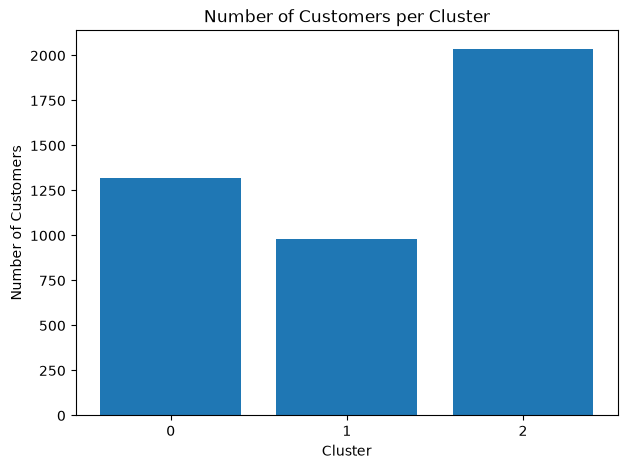

In [64]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.title("Number of Customers per Cluster")

plt.show()

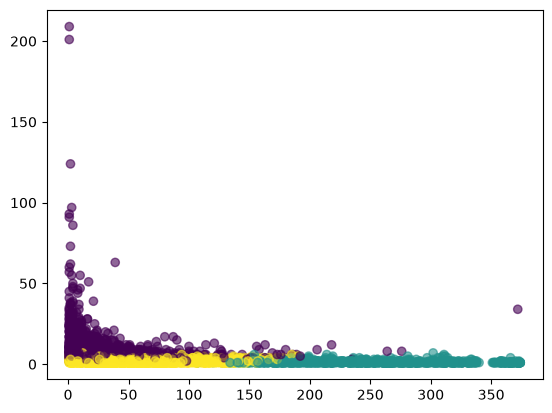

In [65]:
plt.scatter(
    rfm["Recency"],
    rfm["Frequency"],
    c=rfm["Cluster"],
    alpha=0.6
)

In [66]:
# recreate RFM table from existing df and reference_date
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
recency = df.groupby("CustomerID")["InvoiceDate"].max()
recency = (reference_date - recency).dt.days
recency.name = "Recency"

frequency = df.groupby("CustomerID")["InvoiceNo"].nunique()
frequency.name = "Frequency"

monetary = df.groupby("CustomerID")["TotalPrice"].sum()
monetary.name = "Monetary"

rfm = pd.concat([recency, frequency, monetary], axis=1)
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [67]:
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [68]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [69]:
rfm.columns

Index(['Recency', 'Frequency', 'Monetary'], dtype='str')

In [70]:
cluster_names = {
    0: "Loyal Customers",
    1: "At Risk Customers",
    2: "Potential Customers"
}

rfm["Segment"] = rfm["Cluster"].map(cluster_names)

rfm.head()

KeyError: 'Cluster'

In [ ]:
rfm.columns

Index(['Recency', 'Frequency', 'Monetary', 'Cluster', 'Segment'], dtype='str')

In [ ]:
rfm["Segment"].value_counts()

Segment
Potential Customers    2037
Loyal Customers        1320
At Risk Customers       981
Name: count, dtype: int64

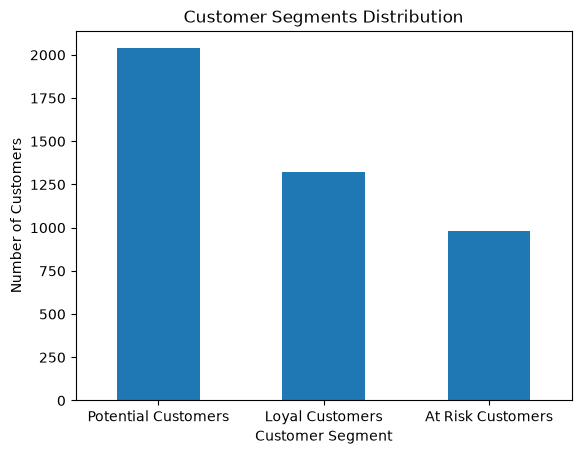

In [ ]:
import matplotlib.pyplot as plt

rfm["Segment"].value_counts().plot(kind="bar")

plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.title("Customer Segments Distribution")
plt.xticks(rotation=0)
plt.show()

In [ ]:
rfm.groupby("Segment")[["Recency", "Frequency", "Monetary"]].mean()

,Recency,Frequency,Monetary
Segment,,,
At Risk Customers,255.107034,1.393476,397.173090
Loyal Customers,30.103788,9.843182,5492.039674
Potential Customers,54.701031,2.048110,612.709731


kostumeret ma besnike kan blerjet me te fundit,me te shpeshta dhe me me shume vlere monetare ,kostumeret ne rrezik kan blerjet me recency me te larte kan blerje jo te shpeshta dhe vlere monetare te vogel

In [ ]:
rfm.to_csv("../data/processed/rfm_customers.csv")

In [ ]:
rfm.head()

,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12346.0,326,1,77183.60,0,Loyal Customers
12347.0,2,7,4310.00,0,Loyal Customers
12348.0,75,4,1797.24,0,Loyal Customers
12349.0,19,1,1757.55,2,Potential Customers
12350.0,310,1,334.40,1,At Risk Customers


In [ ]:
print(rfm.columns)

Index(['Recency', 'Frequency', 'Monetary', 'Cluster', 'Segment'], dtype='str')


In [ ]:
customer_segments = rfm.reset_index()

customer_segments.to_csv(
    "../data/outputs/customer_segments.csv",
    index=False
)

customer_segments.head()

,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346.0,326,1,77183.60,0,Loyal Customers
1,12347.0,2,7,4310.00,0,Loyal Customers
2,12348.0,75,4,1797.24,0,Loyal Customers
3,12349.0,19,1,1757.55,2,Potential Customers
4,12350.0,310,1,334.40,1,At Risk Customers


In [ ]:
from src.rfm import load_cleaned_data, calculate_rfm

df = load_cleaned_data(
    "../data/processed/onlineRetail_cleaned.csv"
)

rfm = calculate_rfm(df)

print(rfm.head())
print(rfm.shape)

ModuleNotFoundError: No module named 'src'

In [ ]:
import os

print(os.getcwd())
print(os.listdir("../src"))

c:\Users\Lenovo\Desktop\Costumer-Segmentation-Recommendation\notebooks
['dataprocessing.py', 'recommendation.py', 'rfm.py', 'segmentation.py']


In [ ]:
import sys
sys.path.append("../")

from src.rfm import load_cleaned_data, calculate_rfm

In [ ]:
import inspect

print(inspect.getsource(src.rfm.load_cleaned_data))

NameError: name 'src' is not defined

In [ ]:
import sys
sys.path.append("..")

In [ ]:
from src.rfm import load_cleaned_data, calculate_rfm

In [ ]:
df = load_cleaned_data(
    "../data/processed/onlineRetail_cleaned.csv"
)

rfm = calculate_rfm(df)

print(rfm.head())
print(rfm.shape)

FileNotFoundError: [Errno 2] No such file or directory: '.../data/processed/onlineRetail_cleaned.csv'

In [ ]:
import sys
sys.path.insert(0, "..")

from src.rfm import load_cleaned_data, calculate_rfm

In [ ]:
df = load_cleaned_data(
    "../data/processed/onlineRetail_cleaned.csv"
)

rfm = calculate_rfm(df)

print(rfm.head())
print(rfm.shape)

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40
(4338, 3)


In [ ]:
import sys
sys.path.insert(0, "..")

In [ ]:
from src.segmentation import (
    prepare_rfm_for_clustering,
    find_optimal_k,
    create_segments
)

In [ ]:
rfm_scaled, scaler = prepare_rfm_for_clustering(rfm)

In [ ]:
print(rfm_scaled.shape)

(4338, 3)


In [ ]:
inertia, silhouette_scores = find_optimal_k(rfm_scaled)

for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K={k}: Silhouette Score = {score:.3f}")

K=2: Silhouette Score = 0.406
K=3: Silhouette Score = 0.416
K=4: Silhouette Score = 0.380
K=5: Silhouette Score = 0.343
K=6: Silhouette Score = 0.330
K=7: Silhouette Score = 0.301
K=8: Silhouette Score = 0.300
K=9: Silhouette Score = 0.283
K=10: Silhouette Score = 0.282


In [ ]:
rfm_segmented, kmeans = create_segments(
    rfm,
    rfm_scaled,
    n_clusters=3
)

In [ ]:
rfm_segmented.head()

,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12346.0,326,1,77183.60,0,Loyal Customers
12347.0,2,7,4310.00,0,Loyal Customers
12348.0,75,4,1797.24,0,Loyal Customers
12349.0,19,1,1757.55,2,Potential Customers
12350.0,310,1,334.40,1,At Risk Customers


In [ ]:
rfm_segmented["Segment"].value_counts()

Segment
Potential Customers    2037
Loyal Customers        1320
At Risk Customers       981
Name: count, dtype: int64

In [ ]:
from src.segmentation import save_segmentation_model

ModuleNotFoundError: No module named 'src'

In [ ]:
import sys
import os

sys.path.append(os.path.abspath(".."))

In [ ]:
from src.segmentation import save_segmentation_model

In [71]:
save_segmentation_model(
    scaler,
    kmeans,
    "../models/customer_segmentation.pkl"
)

In [ ]:
import os

print(os.path.exists("../models/customer_segmentation.pkl"))

True


: 